In [1]:
import torch

X = torch.tensor([[2.]])
target = torch.tensor([[5.]])
W1 = torch.tensor([[1., -1.]], requires_grad=True)
b1 = torch.tensor([1., 1.], requires_grad=True)
W2 = torch.tensor([[2.], [-3.]], requires_grad=True)
b2 = torch.tensor([1.], requires_grad=True)

Z = X @ W1 + b1 # 第一层线性计算
H = torch.relu(Z) # ReLU
out = H @ W2 + b2 # 第二层线性计算
loss = ((out - target) ** 2).mean() / 2 # 平均半平方损失

Z.retain_grad()
H.retain_grad()
loss.backward()

print("out / loss:", out.item(), loss.item())
print("H.grad / Z.grad:", H.grad, Z.grad)
for name, parameter in [("W1", W1), ("b1", b1), ("W2", W2), ("b2", b2)]:
    print(name, parameter.grad, parameter.grad.shape)

out / loss: 7.0 2.0
H.grad / Z.grad: tensor([[ 4., -6.]]) tensor([[4., 0.]])
W1 tensor([[8., 0.]]) torch.Size([1, 2])
b1 tensor([4., 0.]) torch.Size([2])
W2 tensor([[6.],
        [0.]]) torch.Size([2, 1])
b2 tensor([2.]) torch.Size([1])


In [2]:
import torch
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import FashionMNIST
from torchvision.transforms import ToTensor

DATA_ROOT = (
    "../Unit2_Datasets_and_DataLoaders/data"
)
full_train = FashionMNIST(
    DATA_ROOT, train=True, transform=ToTensor(), download=False,
)
train_dataset, val_dataset = random_split(
    full_train, [50000, 10000],
    generator=torch.Generator().manual_seed(42),
)
batch_size = 128
mlp_train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True,
    generator=torch.Generator().manual_seed(123),
)
mlp_train_eval_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
mlp_val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

X_check, y_check = next(iter(mlp_val_loader))
print("samples:", len(train_dataset), len(val_dataset))
print("batch:", X_check.shape, y_check.shape)
assert not (set(train_dataset.indices) & set(val_dataset.indices))

samples: 50000 10000
batch: torch.Size([128, 1, 28, 28]) torch.Size([128])


In [3]:
torch.manual_seed(42)
num_inputs, num_hiddens, num_outputs = 784, 256, 10

mlp_W1 = (torch.randn(num_inputs, num_hiddens) * 0.01).requires_grad_() # 随机小权重，形状 (784, 256)
mlp_b1 = torch.zeros([256, ], requires_grad=True) # 全零偏置，形状 (256,)
mlp_W2 = (torch.randn(num_hiddens, num_outputs) * 0.01).requires_grad_() # 随机小权重，形状 (256, 10)
mlp_b2 = torch.zeros([10, ], requires_grad=True) # 全零偏置，形状 (10,)

mlp_params = [mlp_W1, mlp_b1, mlp_W2, mlp_b2]
for name, parameter in zip(["W1", "b1", "W2", "b2"], mlp_params):
    print(name, tuple(parameter.shape), parameter.requires_grad,
          parameter.is_leaf, parameter.grad)
    assert parameter.requires_grad and parameter.is_leaf

print("parameter count:", sum(p.numel() for p in mlp_params))

W1 (784, 256) True True None
b1 (256,) True True None
W2 (256, 10) True True None
b2 (10,) True True None
parameter count: 203530


In [4]:
def manual_relu(Z):
    return torch.where(Z > 0, Z, 0)  # 条件、条件为真时的值、否则的值

probe = torch.tensor([-2., 0., 3.], requires_grad=True)
probe_out = manual_relu(probe)
probe_out.sum().backward()

print("output:", probe_out.detach())
print("gradient:", probe.grad)
assert torch.equal(probe_out.detach(), torch.relu(probe.detach()))
assert torch.equal(probe.grad, torch.tensor([0., 0., 1.]))

output: tensor([0., 0., 3.])
gradient: tensor([0., 0., 1.])


In [5]:
def manual_mlp(X):
    X_flat = torch.flatten(X, start_dim=1) # 保留第 0 个样本轴，展平剩余轴
    Z = X_flat @ mlp_W1 + mlp_b1 # 使用 mlp_W1、mlp_b1
    H = manual_relu(Z)
    logits = H @ mlp_W2 + mlp_b2 # 使用 mlp_W2、mlp_b2
    return logits

logits_check = manual_mlp(X_check)
print("input:", X_check.shape)
print("logits:", logits_check.shape)
print("requires_grad:", logits_check.requires_grad)

assert logits_check.shape == (X_check.shape[0], num_outputs)
assert torch.isfinite(logits_check).all()
assert logits_check.requires_grad
assert all(p.grad is None for p in mlp_params)

input: torch.Size([128, 1, 28, 28])
logits: torch.Size([128, 10])
requires_grad: True


In [6]:
from torch import nn

names = ["W1", "b1", "W2", "b2"]
loss_fn = nn.CrossEntropyLoss(reduction="mean")
mlp_optimizer = torch.optim.SGD(mlp_params, lr=0.1) # SGD，参数为 mlp_params，学习率 0.1

X_batch, y_batch = next(iter(mlp_train_loader))
before_step = [p.detach().clone() for p in mlp_params]

mlp_optimizer.zero_grad() # 清除旧梯度
logits_batch = manual_mlp(X_batch) # 调用手写 MLP
loss = loss_fn(logits_batch, y_batch) # 用 logits_batch 和 y_batch 计算损失

assert logits_batch.shape == (y_batch.shape[0], num_outputs)
assert y_batch.dtype == torch.long
assert loss.ndim == 0
assert torch.isfinite(loss)
before_loss = loss.item()

loss.backward() # 反向传播

for name, p in zip(names, mlp_params):
    assert p.grad is not None
    assert p.grad.shape == p.shape
    assert torch.isfinite(p.grad).all()
    print(name, "gradient shape:", tuple(p.grad.shape),
          "max |gradient|:", p.grad.abs().max().item())

assert all(
    torch.equal(p.detach(), old)
    for p, old in zip(mlp_params, before_step)
)

mlp_optimizer.step() # 优化器更新参数

changes = [
    (p.detach() - old).abs().max().item()
    for p, old in zip(mlp_params, before_step)
]
assert any(change > 0 for change in changes)

with torch.no_grad():
    after_loss = loss_fn(manual_mlp(X_batch), y_batch).item()

print("loss before / after:", before_loss, after_loss)
print("max parameter changes:", dict(zip(names, changes)))

W1 gradient shape: (784, 256) max |gradient|: 0.005299968179315329
b1 gradient shape: (256,) max |gradient|: 0.004688032902777195
W2 gradient shape: (256, 10) max |gradient|: 0.033868953585624695
b2 gradient shape: (10,) max |gradient|: 0.055856626480817795
loss before / after: 2.302316427230835 2.2909951210021973
max parameter changes: {'W1': 0.0005299968179315329, 'b1': 0.00046880330774001777, 'W2': 0.003386895637959242, 'b2': 0.005585662554949522}


In [7]:
from torch import nn
torch.manual_seed(42)
num_inputs, num_hiddens, num_outputs = 784, 256, 10
mlp_W1 = (torch.randn(num_inputs, num_hiddens) * 0.01).requires_grad_()
mlp_b1 = torch.zeros(num_hiddens, requires_grad=True)
mlp_W2 = (torch.randn(num_hiddens, num_outputs) * 0.01).requires_grad_()
mlp_b2 = torch.zeros(num_outputs, requires_grad=True)
mlp_params = [mlp_W1, mlp_b1, mlp_W2, mlp_b2]
mlp_initial_params = [p.detach().clone() for p in mlp_params]
mlp_train_loader = DataLoader(
    train_dataset, batch_size=128, shuffle=True,
    generator=torch.Generator().manual_seed(123),
)
loss_fn = nn.CrossEntropyLoss(reduction="mean")
mlp_optimizer = torch.optim.SGD(mlp_params, lr=0.1)

In [8]:
def evaluate_mlp(loader):
    loss_sum, correct_sum, sample_count = 0.0, 0, 0
    with torch.no_grad():
        for X, y in loader:
            logits = manual_mlp(X)
            n = y.numel()
            loss_sum += loss_fn(logits, y).item() * n
            correct_sum += (logits.argmax(dim=1) == y).sum().item()
            sample_count += n
    return loss_sum / sample_count, correct_sum / sample_count

In [9]:
print("before:", evaluate_mlp(mlp_train_eval_loader), evaluate_mlp(mlp_val_loader))
mlp_history = []

for epoch in range(10):
    for X_batch, y_batch in mlp_train_loader:
        mlp_optimizer.zero_grad() # 清除旧梯度
        logits = manual_mlp(X_batch) # 手写 MLP 前向计算
        loss = loss_fn(logits, y_batch) # 平均交叉熵
        loss.backward() # 反向传播
        mlp_optimizer.step() # 更新参数

    train_loss, train_acc = evaluate_mlp(mlp_train_eval_loader)
    val_loss, val_acc = evaluate_mlp(mlp_val_loader)
    mlp_history.append((train_loss, train_acc, val_loss, val_acc))
    print(
        f"epoch {epoch + 1:02d}: "
        f"train loss {train_loss:.4f}, acc {train_acc:.1%}; "
        f"val loss {val_loss:.4f}, acc {val_acc:.1%}"
    )

assert len(mlp_history) == 10
assert any(
    not torch.equal(p.detach(), p0)
    for p, p0 in zip(mlp_params, mlp_initial_params)
)

before: (2.3023422235107422, 0.10418) (2.3026619117736815, 0.0986)
epoch 01: train loss 0.5728, acc 80.3%; val loss 0.5848, acc 80.0%
epoch 02: train loss 0.4854, acc 82.7%; val loss 0.4998, acc 82.2%
epoch 03: train loss 0.4450, acc 84.3%; val loss 0.4671, acc 83.3%
epoch 04: train loss 0.4031, acc 86.0%; val loss 0.4222, acc 85.3%
epoch 05: train loss 0.4135, acc 85.2%; val loss 0.4310, acc 84.7%
epoch 06: train loss 0.3871, acc 86.2%; val loss 0.4075, acc 85.3%
epoch 07: train loss 0.3593, acc 87.2%; val loss 0.3823, acc 86.3%
epoch 08: train loss 0.3590, acc 87.1%; val loss 0.3816, acc 86.5%
epoch 09: train loss 0.3522, acc 87.4%; val loss 0.3864, acc 86.1%
epoch 10: train loss 0.3390, acc 87.8%; val loss 0.3697, acc 86.6%


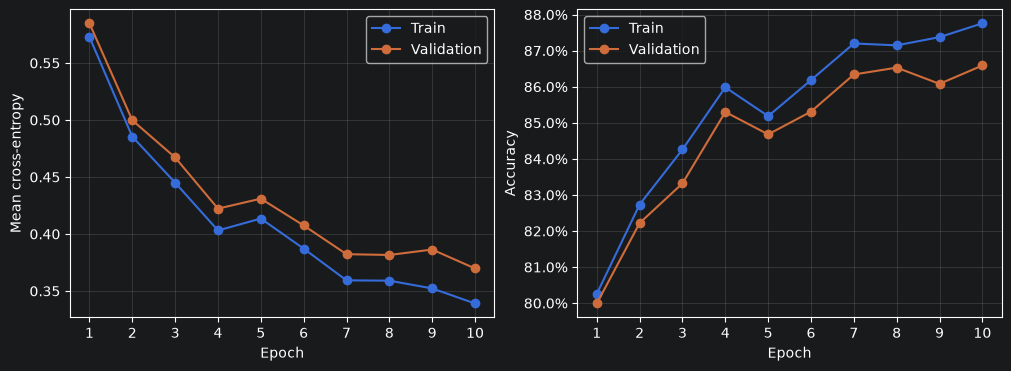

In [10]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

epochs = range(1, len(mlp_history) + 1)
train_losses, train_accs, val_losses, val_accs = zip(*mlp_history)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
for ax, train_values, val_values, ylabel in [
    (axes[0], train_losses, val_losses, "Mean cross-entropy"),
    (axes[1], train_accs, val_accs, "Accuracy"),
]:
    ax.plot(epochs, train_values, marker="o", label="Train")
    ax.plot(epochs, val_values, marker="o", label="Validation")
    ax.set(xlabel="Epoch", ylabel=ylabel)
    ax.set_xticks(epochs)
    ax.grid(alpha=0.25)
    ax.legend()
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
plt.show()

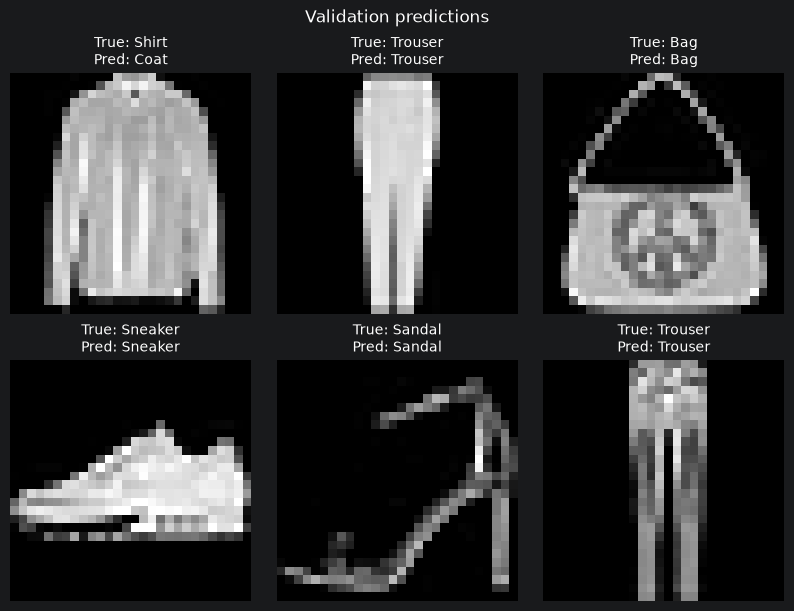

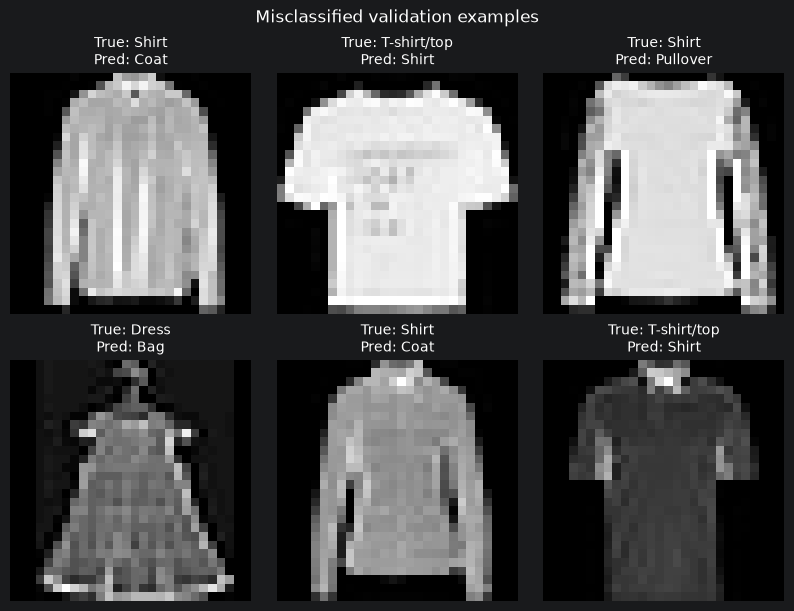

In [11]:
X_vis, y_vis = next(iter(mlp_val_loader))
with torch.no_grad():
    pred_vis = manual_mlp(X_vis).argmax(dim=1)
classes = full_train.classes

def show_mlp_examples(indices, title):
    if not indices:
        print("No matching samples in this batch.")
        return
    fig, axes = plt.subplots(2, 3, figsize=(8, 6), constrained_layout=True)
    fig.suptitle(title)
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, indices[:6]):
        ax.imshow(X_vis[i, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
        ax.set_title(
            f"True: {classes[y_vis[i].item()]}\n"
            f"Pred: {classes[pred_vis[i].item()]}",
            fontsize=10,
        )
    plt.show()

show_mlp_examples(list(range(min(6, len(y_vis)))), "Validation predictions")
wrong_indices = (pred_vis != y_vis).nonzero(as_tuple=True)[0].tolist()
show_mlp_examples(wrong_indices, "Misclassified validation examples")

In [12]:
from torch import nn

class MiniMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(3, 4)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(4, 2)

    def forward(self, X):
        Z = self.fc1(X)
        H = self.relu(Z)
        logits = self.fc2(H)
        return logits

In [13]:
import torch
from torch import nn

class FashionMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten(start_dim=1) # TODO：保留 batch 轴，展平每张图片
        self.fc1 = nn.Linear(784, 256) # TODO：784 → 256
        self.relu = nn.ReLU() # TODO：ReLU
        self.fc2 = nn.Linear(256, 10) # TODO：256 → 10

    def forward(self, X):
        X_flat = self.flatten(X) # TODO：调用模型保存的展平模块
        Z = self.fc1(X_flat) # TODO：调用第一层
        H = self.relu(Z) # TODO：调用 ReLU
        logits = self.fc2(H) # TODO：调用第二层
        return logits

framework_mlp = FashionMLP()

X_probe = torch.zeros(4, 1, 28, 28)
logits_probe = framework_mlp(X_probe)

print(framework_mlp)
print("输出形状：", logits_probe.shape)

assert logits_probe.shape == (4, 10)

FashionMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)
输出形状： torch.Size([4, 10])


In [14]:
for name, p in framework_mlp.named_parameters():
    print(
        name,
        "shape:", tuple(p.shape),
        "requires_grad:", p.requires_grad,
        "device:", p.device,
    )

print(
    "参数元素总数:",
    sum(p.numel() for p in framework_mlp.parameters()),
)

fc1.weight shape: (256, 784) requires_grad: True device: cpu
fc1.bias shape: (256,) requires_grad: True device: cpu
fc2.weight shape: (10, 256) requires_grad: True device: cpu
fc2.bias shape: (10,) requires_grad: True device: cpu
参数元素总数: 203530


In [15]:
practice_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

device_demo_model = FashionMLP().to(practice_device)

device_demo_X = torch.zeros(4, 1, 28, 28)
device_demo_X = device_demo_X.to(practice_device)

with torch.no_grad():
    device_demo_logits = device_demo_model(device_demo_X)

print("参数设备:", device_demo_model.fc1.weight.device)
print("输入设备:", device_demo_X.device)
print("输出设备:", device_demo_logits.device)
print("输出形状:", device_demo_logits.shape)

参数设备: cpu
输入设备: cpu
输出设备: cpu
输出形状: torch.Size([4, 10])


In [16]:
# 从训练前的快照建立独立参数，供这次检查使用
check_manual_params = [
    p.detach().cpu().clone().requires_grad_()
    for p in mlp_initial_params
]
check_W1, check_b1, check_W2, check_b2 = check_manual_params

def check_manual_forward(X):
    X_flat = torch.flatten(X, start_dim=1)
    H = manual_relu(X_flat @ check_W1 + check_b1)
    return H @ check_W2 + check_b2

# 两版统一在 CPU 上检查
check_model = FashionMLP().to("cpu")

with torch.no_grad():
    check_model.fc1.weight.copy_(check_W1.T)  # TODO：第一层权重
    check_model.fc1.bias.copy_(check_b1)    # TODO：第一层偏置
    check_model.fc2.weight.copy_(check_W2.T)  # TODO：第二层权重
    check_model.fc2.bias.copy_(check_b2)    # TODO：第二层偏置

# 从训练集取同一批样本，不消耗正式训练加载器的打乱顺序
check_X, check_y = next(iter(mlp_train_eval_loader))
check_X = check_X.to("cpu")
check_y = check_y.to("cpu")

check_loss_fn = nn.CrossEntropyLoss(reduction="mean")

# 前向计算放在 no_grad 块外，后面还要检查反向传播
check_manual_logits = check_manual_forward(check_X) # TODO：调用这次检查的手写函数
check_framework_logits = check_model(check_X) # TODO：调用这次检查的框架模型

check_manual_loss = check_loss_fn(check_manual_logits, check_y) # TODO：手写版平均交叉熵
check_framework_loss = check_loss_fn(check_framework_logits, check_y) # TODO：框架版平均交叉熵

In [17]:
torch.testing.assert_close(
    check_framework_logits, check_manual_logits,
    rtol=1e-5, atol=1e-6,
)
torch.testing.assert_close(
    check_framework_loss, check_manual_loss,
    rtol=1e-5, atol=1e-6,
)

print("输出形状:", check_framework_logits.shape)
print(
    "输出最大绝对差:",
    (check_framework_logits - check_manual_logits).abs().max().item(),
)
print(
    "两版 loss:",
    check_manual_loss.item(),
    check_framework_loss.item(),
)
print("前向计算检查通过")

输出形状: torch.Size([128, 10])
输出最大绝对差: 0.0
两版 loss: 2.3046069145202637 2.3046069145202637
前向计算检查通过


In [18]:
check_manual_optimizer = torch.optim.SGD(
    check_manual_params, lr=0.1,  # TODO：手写版参数列表
)
check_framework_optimizer = torch.optim.SGD(
    check_model.parameters(), lr=0.1,  # TODO：框架版参数
)

# 保存更新前的手写参数，稍后检查参数是否改变
check_before = [p.detach().clone() for p in check_manual_params]

check_manual_optimizer.zero_grad()
check_framework_optimizer.zero_grad()

check_manual_loss = check_loss_fn(
    check_manual_forward(check_X), check_y,
)
check_framework_loss = check_loss_fn(
    check_model(check_X), check_y,
)

check_manual_loss.backward() # TODO：手写版反向传播
check_framework_loss.backward() # TODO：框架版反向传播

In [19]:
expected_grads = {
    "fc1.weight": check_W1.grad.T,
    "fc1.bias": check_b1.grad,
    "fc2.weight": check_W2.grad.T,
    "fc2.bias": check_b2.grad,
}

for name, p in check_model.named_parameters():
    torch.testing.assert_close(
        p.grad, expected_grads[name],
        rtol=1e-5, atol=1e-6,
    )
    print(name, "梯度检查通过，形状:", tuple(p.grad.shape))

# backward 之后、step 之前，参数数值应保持不变
assert all(
    torch.equal(p.detach(), old)
    for p, old in zip(check_manual_params, check_before)
)

fc1.weight 梯度检查通过，形状: (256, 784)
fc1.bias 梯度检查通过，形状: (256,)
fc2.weight 梯度检查通过，形状: (10, 256)
fc2.bias 梯度检查通过，形状: (10,)


In [20]:
check_manual_optimizer.step() # TODO：手写版优化器更新
check_framework_optimizer.step() # TODO：框架版优化器更新

expected_params = {
    "fc1.weight": check_W1.T,
    "fc1.bias": check_b1,
    "fc2.weight": check_W2.T,
    "fc2.bias": check_b2,
}

for name, p in check_model.named_parameters():
    torch.testing.assert_close(
        p.detach(), expected_params[name].detach(),
        rtol=1e-5, atol=1e-6,
    )
    print(name, "更新后参数检查通过")

# 确认确实发生了更新，避免两边都没有更新却仍然相同
assert any(
    not torch.equal(p.detach(), old)
    for p, old in zip(check_manual_params, check_before)
)
print("梯度与一次参数更新的对应检查通过")

fc1.weight 更新后参数检查通过
fc1.bias 更新后参数检查通过
fc2.weight 更新后参数检查通过
fc2.bias 更新后参数检查通过
梯度与一次参数更新的对应检查通过


In [21]:
framework_device = torch.device("cpu")
framework_mlp = FashionMLP().to(framework_device)

initial_W1, initial_b1, initial_W2, initial_b2 = mlp_initial_params

with torch.no_grad():
    framework_mlp.fc1.weight.copy_(initial_W1.T)
    framework_mlp.fc1.bias.copy_(initial_b1)
    framework_mlp.fc2.weight.copy_(initial_W2.T)
    framework_mlp.fc2.bias.copy_(initial_b2)

framework_mlp_train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    generator=torch.Generator().manual_seed(123),
)

framework_loss_fn = nn.CrossEntropyLoss(reduction="mean")
framework_mlp_optimizer = torch.optim.SGD(
    framework_mlp.parameters(), lr=0.1,
)

In [22]:
def evaluate_framework_mlp(loader):
    framework_mlp.eval() # TODO: 把 framework_mlp 切换到评估模式

    loss_sum, correct_sum, sample_count = 0.0, 0, 0

    with torch.no_grad(): # TODO: 关闭本次评估的梯度记录
        for X, y in loader:
            X = X.to(framework_device)
            y = y.to(framework_device)

            logits = framework_mlp(X)
            n = y.numel()

            loss_sum += framework_loss_fn(logits, y).item() * n
            correct_sum += (logits.argmax(dim=1) == y).sum().item()
            sample_count += n

        return loss_sum / sample_count, correct_sum / sample_count

In [23]:
print(
    "before: ",
    evaluate_framework_mlp(mlp_train_eval_loader),
    evaluate_framework_mlp(mlp_val_loader),
)

framework_mlp_history = []

for epoch in range(10):
    framework_mlp.train() # TODO: 把 framework_mlp 切换到训练模式

    for X_batch, y_batch in framework_mlp_train_loader:
        X_batch = X_batch.to(framework_device)
        y_batch = y_batch.to(framework_device)

        framework_mlp_optimizer.zero_grad() # TODO: 清除框架版优化器管理的旧梯度
        logits = framework_mlp(X_batch) # TODO: 通过框架版模型预测
        loss = framework_loss_fn(logits, y_batch) # TODO: 通过 framework_loss_fn 计算损失
        loss.backward() # TODO: 反向传播
        framework_mlp_optimizer.step() # TODO: 优化器更新参数

    train_loss, train_acc = evaluate_framework_mlp(
        mlp_train_eval_loader,
    )
    val_loss, val_acc = evaluate_framework_mlp(mlp_val_loader)

    framework_mlp_history.append(
        (train_loss, train_acc, val_loss, val_acc)
    )

    print(
        f"epoch {epoch + 1:02d}: "
        f"train_loss: {train_loss:.4f}, acc {train_acc:.1%}; "
        f"val_loss: {val_loss:.4f}, acc {val_acc:.1%}"
    )

before:  (2.3023422235107422, 0.10418) (2.3026619117736815, 0.0986)
epoch 01: train_loss: 0.5728, acc 80.3%; val_loss: 0.5848, acc 80.0%
epoch 02: train_loss: 0.4851, acc 82.8%; val_loss: 0.4995, acc 82.2%
epoch 03: train_loss: 0.4457, acc 84.2%; val_loss: 0.4678, acc 83.2%
epoch 04: train_loss: 0.4031, acc 86.0%; val_loss: 0.4225, acc 85.3%
epoch 05: train_loss: 0.4136, acc 85.1%; val_loss: 0.4306, acc 84.7%
epoch 06: train_loss: 0.3868, acc 86.2%; val_loss: 0.4077, acc 85.1%
epoch 07: train_loss: 0.3593, acc 87.2%; val_loss: 0.3823, acc 86.4%
epoch 08: train_loss: 0.3578, acc 87.2%; val_loss: 0.3803, acc 86.6%
epoch 09: train_loss: 0.3543, acc 87.3%; val_loss: 0.3884, acc 86.1%
epoch 10: train_loss: 0.3374, acc 87.8%; val_loss: 0.3679, acc 86.6%


In [24]:
assert len(framework_mlp_history) == len(mlp_history) == 10

manual_records = torch.tensor(mlp_history, dtype=torch.float64)
framework_records = torch.tensor(
    framework_mlp_history, dtype=torch.float64
)

print("手写版最后一轮: ", mlp_history[-1])
print("框架版最后一轮: ", framework_mlp_history[-1])
print(
    "各列在10轮中的最大绝对差: ",
    (framework_records - manual_records).abs().amax(dim=0)
)

手写版最后一轮:  (0.33901971877098086, 0.87758, 0.3697373649597168, 0.8659)
框架版最后一轮:  (0.3374010068416595, 0.87758, 0.367921855711937, 0.8664)
各列在10轮中的最大绝对差:  tensor([0.0021, 0.0007, 0.0020, 0.0019], dtype=torch.float64)


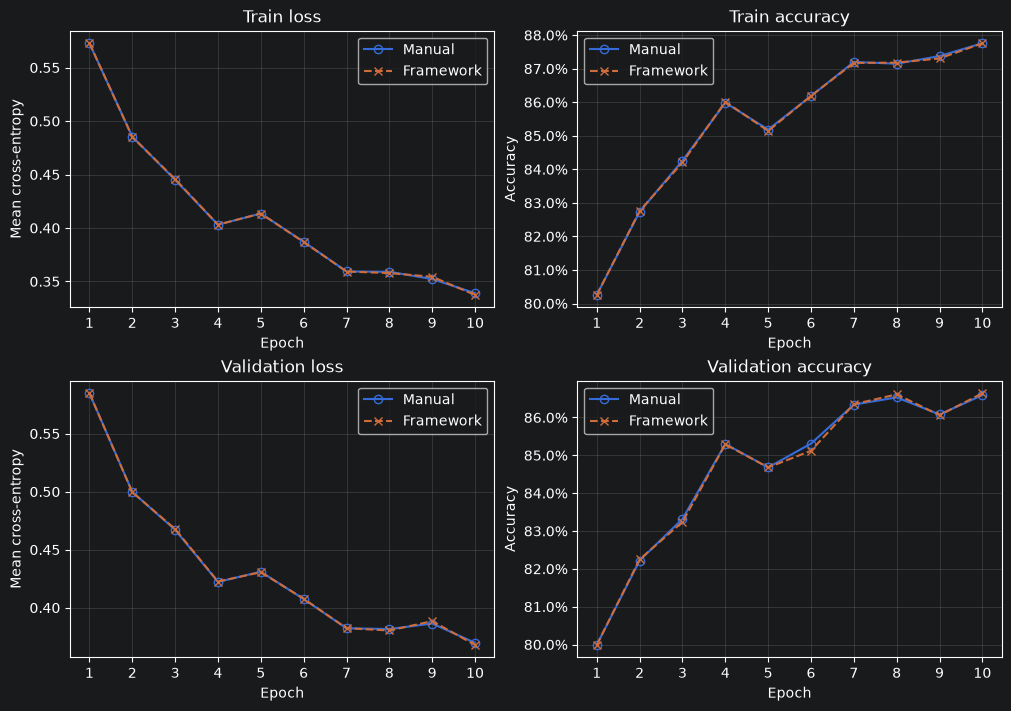

In [25]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

manual_plot = torch.tensor(mlp_history, dtype=torch.float64).numpy()
framework_plot = torch.tensor(
    framework_mlp_history, dtype=torch.float64,
).numpy()

epochs = range(1, len(mlp_history) + 1)
titles = [
    "Train loss", "Train accuracy",
    "Validation loss", "Validation accuracy",
]

fig, axes = plt.subplots(
    2, 2, figsize=(10, 7), constrained_layout=True,
)

for i, (ax, title) in enumerate(zip(axes.flat, titles)):
    ax.plot(
        epochs, manual_plot[:, i], "-o",
        markerfacecolor="none", label="Manual",
    )
    ax.plot(
        epochs, framework_plot[:, i], "--x",
        label="Framework",
    )
    ax.set(title=title, xlabel="Epoch")
    ax.set_xticks(epochs)
    ax.grid(alpha=0.25)
    ax.legend()

    if i in (1, 3):
        ax.set_ylabel("Accuracy")
        ax.yaxis.set_major_formatter(PercentFormatter(1))
    else:
        ax.set_ylabel("Mean cross-entropy")

plt.show()